# 02 · Where to put the levels

STE papers almost always use a **uniform** grid ($\text{int-}b$). vvtk_quant lets the levels go anywhere. Before
training anything, we ask a static question: **for a given weight distribution and $b$ bits, which levels lose the
least information?**

| Step | What you will see |
|---|---|
| 1 | weight distributions: Gaussian, Laplace, heavy-tailed |
| 2 | five level families: uniform, equal-probability, companding, Lloyd-Max (MSE-optimal), FP4 |
| 3 | their mean squared error vs bits |
| 3b | the v0.x equal-probability method against the new levels |
| 4 | how often each level is used (entropy) |
| 5 | per-tensor vs shared levels |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch
import matplotlib.pyplot as plt
from vvtk_quant import uniform_levels, eqprob_levels, lloyd_levels, companding_levels, fp_levels, fp_values, mse
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(0)

## Step 1 · Weight distributions

Trained weights are roughly zero-mean and bell-shaped, but with **heavier tails** than a Gaussian, and in LLMs a few
large outliers. We simulate three cases with the same standard deviation (0.02, a typical scale):
Gaussian, Laplace, and Student-$t$ with 3 degrees of freedom (heavy tails).

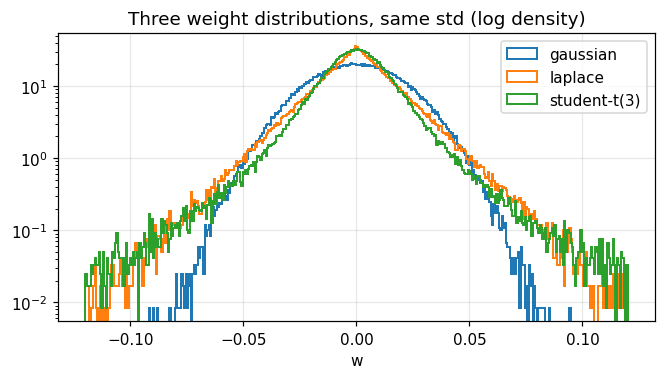

     gaussian: std=0.0200  max|w|=0.095  max/std=4.7
      laplace: std=0.0200  max|w|=0.165  max/std=8.3
 student-t(3): std=0.0200  max|w|=0.720  max/std=36.0


In [2]:
n = 200_000
dists = {
    "gaussian": rng.normal(0, 1, n),
    "laplace": rng.laplace(0, 1, n),
    "student-t(3)": rng.standard_t(3, n),
}
dists = {k: 0.02 * v / v.std() for k, v in dists.items()}

plt.figure(figsize=(7, 3.4))
for k, v in dists.items():
    plt.hist(v, bins=400, range=(-0.12, 0.12), histtype="step", density=True, label=k, lw=1.3)
plt.yscale("log"); plt.title("Three weight distributions, same std (log density)"); plt.legend(); plt.xlabel("w"); plt.show()
for k, v in dists.items():
    print(f"{k:>13}: std={v.std():.4f}  max|w|={np.abs(v).max():.3f}  max/std={np.abs(v).max() / v.std():.1f}")

## Step 2 · Four families of levels

**Uniform** (symmetric, with a zero level, the standard int-$b$ of STE/LSQ papers), scaled to $a=\max|w|$:

$$l_k = a\,\frac{k}{h}, \quad k=-h,\dots,h, \quad h = 2^{b-1}-1 \quad (2^b-1 \text{ levels}).$$

> 📘 **Common practice**: the int-$b$ grid of TensorFlow Lite, PyTorch, GPTQ, LSQ (arXiv:1806.08342, 2210.17323, 1902.08153).

**Equal-probability**: every level owns the same mass $1/L$. Level $k$ is the $(k+\tfrac12)/L$ quantile of the
weights, $l_k = F^{-1}\big(\tfrac{k+1/2}{L}\big)$. Dense where the weights are dense. (v0.x used the upper edge of each
bin, quantile $(k+1)/L$; `eqprob_levels(..., mid=False)` keeps that.)

> 📘 **Common practice** in a close form: NF4 (QLoRA, arXiv:2305.14314) puts 4-bit levels at the quantiles of a
> **normal** distribution. 🧪 **vvtk_quant (small modification):** the quantiles of each tensor's **own** histogram
> (no normality assumption), per tensor.

**Lloyd-Max**: the levels that minimise the mean squared error

$$D = \mathbb{E}\big[(w - Q(w))^2\big].$$

Setting $\partial D/\partial l_k = 0$ and $\partial D / \partial m_k = 0$ gives two conditions, iterated to a fixed point
(this is 1-D k-means):

$$m_k = \tfrac12 (l_k + l_{k+1}) \qquad\text{and}\qquad l_k = \mathbb{E}\,[\,w \mid m_{k-1} < w \le m_k\,].$$

Every level is the **centroid (the "MSE anchor") of its bin**. These are the anchor points we will pull weights towards
in notebook 05.

> 📘 **Common practice** for non-uniform weight quantization: Deep Compression's k-means weight sharing
> (arXiv:1510.00149) and SqueezeLLM's sensitivity-weighted k-means (arXiv:2306.07629). The theory is Lloyd (1982) and
> Max (1960).

**Companding** (Bennett 1948, Panter & Dite 1951): for many levels, the MSE-optimal *density* of levels is

$$\lambda(w) \propto p(w)^{1/3},$$

so the levels are the quantiles of $p^{1/3}$ instead of $p$ (equal-probability would be $p^{1}$, uniform $p^{0}$).
It is a closed-form near-optimum; `lloyd_levels` starts from it and iterates.

> 📗 **Classic theory, rarely used in deep learning.** Bennett's high-resolution analysis; read Gray & Neuhoff,
> *Quantization*, IEEE Trans. Inf. Theory 44(6), 1998. Using it to initialise Lloyd is our engineering choice.

**FP4 E2M1**: the 4-bit float of the OCP microscaling formats, $\{0, 0.5, 1, 1.5, 2, 3, 4, 6\}$ and negatives, scaled
so that $6 \mapsto \max|w|$. Log-spaced: fine near zero, coarse in the tails.

> 📘 **Common practice**: FP8/FP4 with shared scales are the MX formats of current hardware (arXiv:2310.10537).

FP4 E2M1 values: [-6.0, -4.0, -3.0, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]


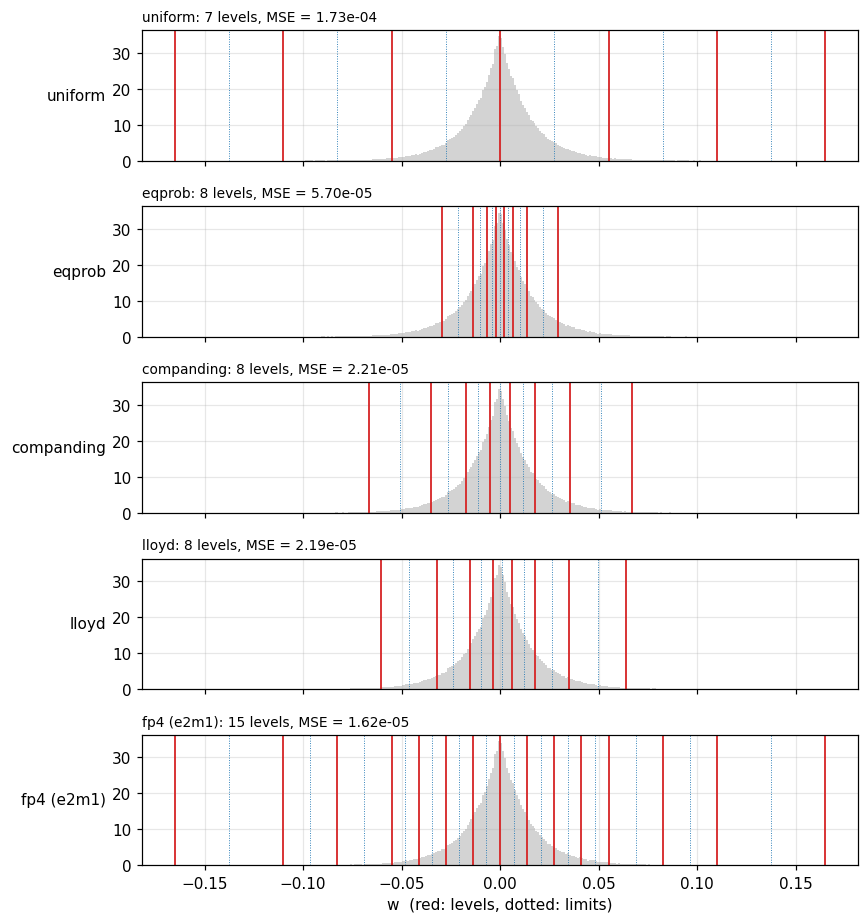

In [3]:
print("FP4 E2M1 values:", fp_values(2, 1).tolist())
w = dists["laplace"]
b = 3
fams = {
    "uniform": uniform_levels(w, b=b),
    "eqprob": eqprob_levels(w, b=b),
    "companding": companding_levels(w, b=b),
    "lloyd": lloyd_levels(w, b=b),
    "fp4 (e2m1)": fp_levels(w, 2, 1),
}
fig, axs = plt.subplots(len(fams), 1, figsize=(8, 8.5), sharex=True)
for ax, (name, lv) in zip(axs, fams.items()):
    ax.hist(w, bins=300, range=(-0.15, 0.15), color="lightgray", density=True)
    for l in lv: ax.axvline(l, color="C3", lw=1.2)
    lim = (lv[:-1] + lv[1:]) / 2
    for m in lim: ax.axvline(m, color="C0", lw=0.6, ls=":")
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    ax.set_title(f"{name}: {len(lv)} levels, MSE = {mse(w, lv):.2e}", fontsize=9, loc="left")
axs[-1].set_xlabel("w  (red: levels, dotted: limits)"); plt.tight_layout(); plt.show()

Note how the uniform grid wastes most of its levels in the tails where almost no weight lives (it is scaled to the
largest outlier), while equal-probability and Lloyd-Max put them where the mass is.

## Step 3 · MSE vs bits

We report the **signal-to-quantization-noise ratio** $\text{SQNR} = 10\log_{10}\big(\mathbb{E}[w^2]/D\big)$ in dB.
A uniform quantizer on a bounded signal gains about 6 dB per bit; watch what happens with tails.

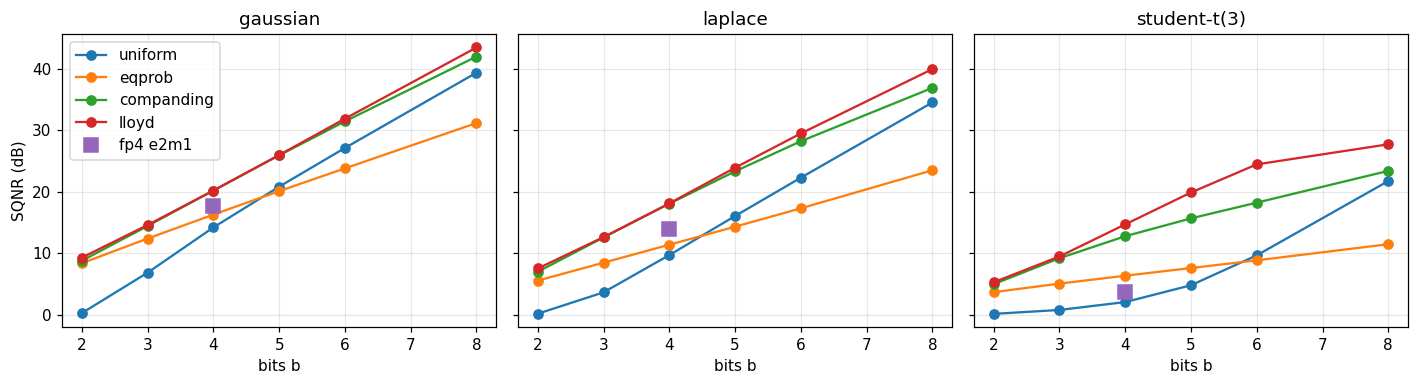

In [4]:
bits = [2, 3, 4, 5, 6, 8]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (dn, w) in zip(axs, dists.items()):
    p = np.mean(w ** 2)
    for name, f in [("uniform", uniform_levels), ("eqprob", eqprob_levels), ("companding", companding_levels), ("lloyd", lloyd_levels)]:
        ax.plot(bits, [10 * np.log10(p / mse(w, f(w, b=bb))) for bb in bits], "o-", label=name)
    ax.plot([4], [10 * np.log10(p / mse(w, fp_levels(w, 2, 1)))], "s", ms=9, label="fp4 e2m1")
    ax.set_title(dn); ax.set_xlabel("bits b")
axs[0].set_ylabel("SQNR (dB)"); axs[0].legend(); plt.tight_layout(); plt.show()

In [5]:
w = dists["student-t(3)"]
print(f"{'bits':>4} | {'uniform':>9} | {'eqprob':>9} | {'eqprob v0':>9} | {'compand':>9} | {'lloyd':>9}   (MSE x 1e6, student-t)")
for bb in bits:
    r = [mse(w, uniform_levels(w, b=bb)), mse(w, eqprob_levels(w, b=bb)),
         mse(w, eqprob_levels(w, b=bb, mid=False)), mse(w, companding_levels(w, b=bb)), mse(w, lloyd_levels(w, b=bb))]
    print(f"{bb:>4} | " + " | ".join(f"{1e6 * x:9.3f}" for x in r))

bits |   uniform |    eqprob | eqprob v0 |   compand |     lloyd   (MSE x 1e6, student-t)
   2 |   388.252 |   172.162 |   236.573 |   127.426 |   118.914


   3 |   335.268 |   124.942 |   162.668 |    48.234 |    45.182


   4 |   249.486 |    92.905 |   118.273 |    21.169 |    13.574


   5 |   132.861 |    69.729 |    87.727 |    10.845 |     4.111


   6 |    43.334 |    52.239 |    65.458 |     6.015 |     1.434


   8 |     2.678 |    28.555 |    35.619 |     1.831 |     0.676


## Step 3b · The v0.x equal-probability method against the new levels

The first versions of the library (v0.x) also put the levels at equal-probability points, but they did it in a
different way. This step runs the **original functions** `calibrate_quant_v0` and `calibrate_quant_v1` next to
`eqprob_levels`, so that the differences can be measured.

| | v0.x `calibrate_quant_v1` | v0.x `calibrate_quant_v0` | new `eqprob_levels` |
|---|---|---|---|
| Where the quantiles come from | histogram with 512 equal-width bins, cumulative sum, linear interpolation | the same | `np.quantile` of the weights themselves |
| Which quantiles | $1/L, 2/L, \dots, 1$ (the **upper edge** of each bin of mass) | the same | $(k+\tfrac12)/L$ (the **centre** of each bin of mass), or the v0.x ones with `mid=False` |
| Tensors | one table **per tensor** | one table **shared by all tensors** | one table per tensor |
| Largest level | always $\max w$ (quantile 1) | always the largest weight of all tensors | the $(L-\tfrac12)/L$ quantile, inside the data |

Three things follow from this. The top level of v0.x is the single largest weight, so one outlier decides where the
last level goes. The levels of v0.x sit at the top of their bin of mass, which shifts every level upward by half a
bin. And the 512-bin histogram has a limited resolution: at 8 bits there are 256 levels but only 512 bins, and in a
heavy-tailed tensor most bins are almost empty.

We use three tensors with different scales (as in Step 5), so that the shared table of v0 shows what it costs.

In [6]:
import torch.nn as nn
from vvtk_quant.levels import calibrate_quant_v0, calibrate_quant_v1


class Holder(nn.Module):
    # a module whose parameters are the tensors we want to quantize (names w0, w1, ...)
    def __init__(self, ws):
        super().__init__()
        for i, w in enumerate(ws):
            setattr(self, f"w{i}", nn.Parameter(torch.tensor(w, dtype=torch.float32)))


def rel_mse(w, lv):
    return mse(w, lv) / np.mean(w ** 2)


scales = [0.01, 0.03, 0.08]
tens = [s * v / v.std() for s, v in zip(scales, (rng.standard_t(3, 50_000) for _ in scales))]
keys = [f"w{i}" for i in range(len(tens))]
hold = Holder(tens)

variants = ["v0 (shared, hist, upper)", "v1 (per tensor, hist, upper)", "eqprob mid=False (exact, upper)",
            "eqprob mid=True (exact, centre)", "lloyd"]
print("relative MSE  D / E[w^2], averaged over the three tensors (student-t, scales 0.01 / 0.03 / 0.08)")
print(f"{'bits':>4} | " + " | ".join(f"{v:>31}" for v in variants))
for bb in [2, 3, 4, 6, 8]:
    e0 = calibrate_quant_v0(hold, qkeys=keys, b=bb)
    e1 = calibrate_quant_v1(hold, qkeys=keys, b=bb)
    rows = [
        [rel_mse(w, e0[k]) for w, k in zip(tens, keys)],
        [rel_mse(w, e1[k]) for w, k in zip(tens, keys)],
        [rel_mse(w, eqprob_levels(w, b=bb, mid=False)) for w in tens],
        [rel_mse(w, eqprob_levels(w, b=bb)) for w in tens],
        [rel_mse(w, lloyd_levels(w, b=bb)) for w in tens],
    ]
    print(f"{bb:>4} | " + " | ".join(f"{np.mean(r):31.3e}" for r in rows))

relative MSE  D / E[w^2], averaged over the three tensors (student-t, scales 0.01 / 0.03 / 0.08)
bits |        v0 (shared, hist, upper) |    v1 (per tensor, hist, upper) | eqprob mid=False (exact, upper) | eqprob mid=True (exact, centre) |                           lloyd
   2 |                       6.087e-01 |                       5.590e-01 |                       5.598e-01 |                       4.230e-01 |                       2.930e-01


   3 |                       3.737e-01 |                       3.742e-01 |                       3.747e-01 |                       3.047e-01 |                       1.129e-01
   4 |                       2.359e-01 |                       2.641e-01 |                       2.645e-01 |                       2.270e-01 |                       3.217e-02


   6 |                       1.087e-01 |                       1.372e-01 |                       1.376e-01 |                       1.252e-01 |                       4.116e-03


   8 |                       5.340e-02 |                       6.528e-02 |                       6.531e-02 |                       6.533e-02 |                       1.857e-03


Now the levels themselves, for the tensor with scale 0.03 at 3 bits. Compare the position of the top level of v1
(the largest weight) with the others, and the shift between `mid=False` (upper edge) and `mid=True` (centre).

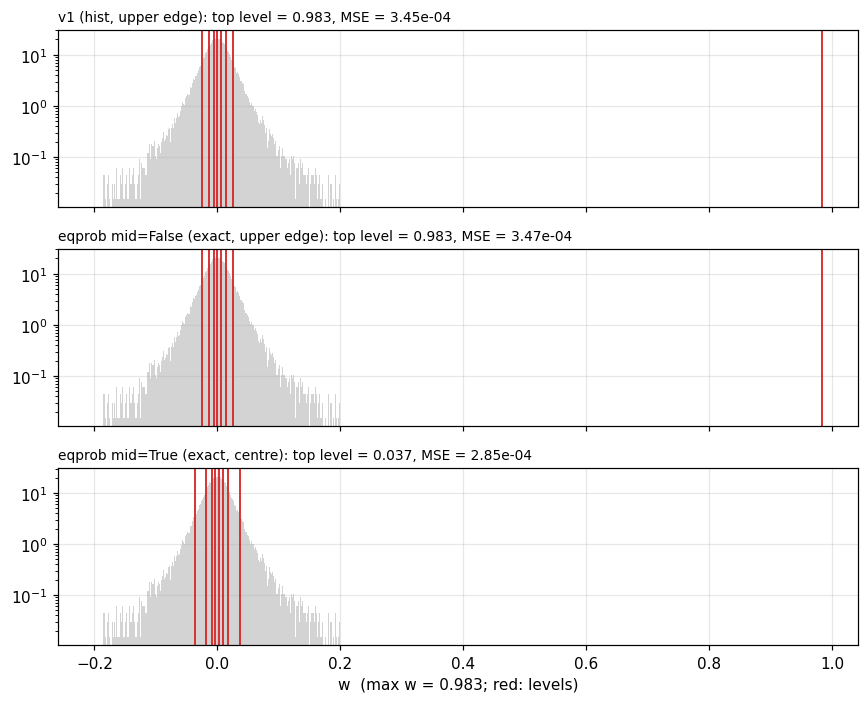

v1 vs mid=False, largest difference between levels: 0.00017085796910206244
v1 top level == max w: True


In [7]:
w, b = tens[1], 3
e1 = np.array(calibrate_quant_v1(hold, qkeys=keys, b=b)["w1"])
fams = {"v1 (hist, upper edge)": e1,
        "eqprob mid=False (exact, upper edge)": eqprob_levels(w, b=b, mid=False),
        "eqprob mid=True (exact, centre)": eqprob_levels(w, b=b)}
fig, axs = plt.subplots(len(fams), 1, figsize=(8, 6.5), sharex=True)
for ax, (name, lv) in zip(axs, fams.items()):
    ax.hist(w, bins=300, range=(-0.2, 0.2), color="lightgray", density=True)
    for l in lv: ax.axvline(l, color="C3", lw=1.2)
    ax.set_yscale("log")
    ax.set_title(f"{name}: top level = {lv[-1]:.3f}, MSE = {mse(w, lv):.2e}", fontsize=9, loc="left")
axs[-1].set_xlabel(f"w  (max w = {w.max():.3f}; red: levels)"); plt.tight_layout(); plt.show()
print("v1 vs mid=False, largest difference between levels:", np.abs(e1 - eqprob_levels(w, b=b, mid=False)).max())
print("v1 top level == max w:", np.isclose(e1[-1], w.max(), rtol=1e-4))

### Reading the results of Step 3b (one run, three student-t tensors)

* **The histogram costs nothing.** `v1` (histogram with 512 bins) and `eqprob(mid=False)` (exact quantiles) agree to
  within 0.1 % in MSE at every bit width, even at 8 bits, where 256 levels share 512 bins. The largest difference
  between two levels is about 2e-4. The two methods are the same method here.
* **The top level at the maximum weight changes little.** In the figure, the top level of `v1` is the largest weight.
  The MSE is still the same as for `mid=False`, because only one level is affected.
* **The centre of the bin helps at low bit widths.** Moving from `mid=False` to `mid=True` lowers the relative MSE
  from 0.560 to 0.423 at 2 bits, from 0.375 to 0.305 at 3 bits, and from 0.265 to 0.227 at 4 bits. At 8 bits the two
  are equal. Lloyd is still far ahead of both (0.293 at 2 bits, 0.0019 at 8 bits).
* **The shared table of `v0` looks better than `v1` at 4 bits and above, but this is misleading.** The shared table
  gives most levels to the tensor with the smallest scale. At 4 bits the relative MSE of that tensor falls from 0.247
  to 0.065, while the tensor with the largest scale gets worse, from 0.275 to 0.432. An unweighted average of relative
  MSE rewards this trade. I checked that exact quantiles of the pooled weights give the same numbers as `v0`, so the
  cause is the shared table and not the histogram. Notebook 03 shows the cost of sharing on a real network.

## Step 4 · How often is each level used?

The index of a weight is what we store. If some levels are almost never used we are wasting bits. The **entropy**
of the index distribution,

$$H = -\sum_k p_k \log_2 p_k \le b,$$

measures how many bits per weight carry information. Equal-probability levels reach $H=b$ by construction;
Lloyd-Max trades some entropy for lower MSE; uniform-absmax wastes many bits on heavy tails.

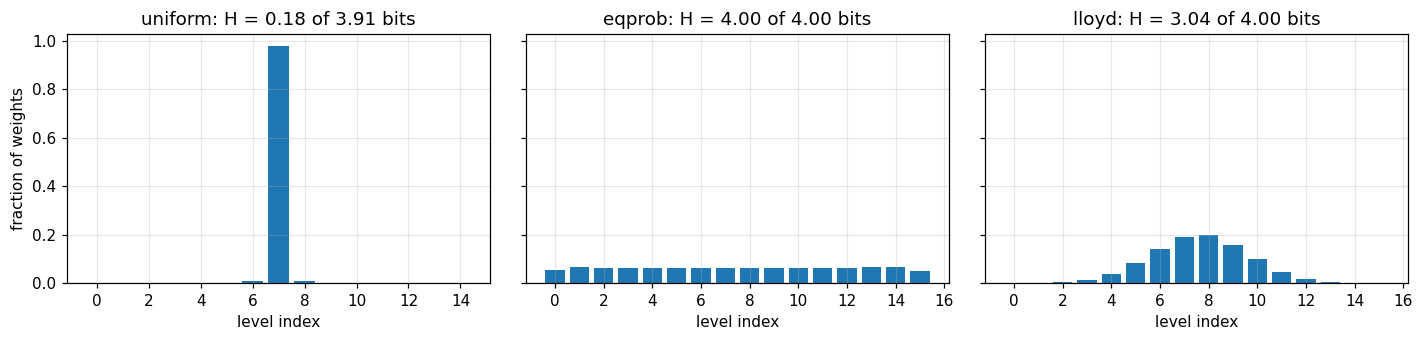

In [8]:
w = dists["student-t(3)"]
b = 4
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (name, f) in zip(axs, [("uniform", uniform_levels), ("eqprob", eqprob_levels), ("lloyd", lloyd_levels)]):
    lv = f(w, b=b)
    idx = np.searchsorted((lv[:-1] + lv[1:]) / 2, w)
    p = np.bincount(idx, minlength=len(lv)) / len(w)
    H = -(p[p > 0] * np.log2(p[p > 0])).sum()
    ax.bar(range(len(lv)), p); ax.set_title(f"{name}: H = {H:.2f} of {np.log2(len(lv)):.2f} bits"); ax.set_xlabel("level index")
axs[0].set_ylabel("fraction of weights"); plt.tight_layout(); plt.show()

## Step 5 · Per-tensor vs shared levels

Each tensor can have its own levels (16 floats per tensor at 4 bits: negligible storage) or all tensors can share
one table (needed by some hardware). Layers have different scales, so a shared table pays a price. A toy model with
three layers of different scales:

> 📘 **Common practice**: per-tensor or per-channel quantization parameters are standard (Krishnamoorthi 2018,
> arXiv:1806.08342).

In [9]:
layers = {f"layer{i}": s * rng.laplace(0, 1, 50_000) for i, s in enumerate([0.01, 0.03, 0.08])}
allw = np.concatenate(list(layers.values()))
shared = lloyd_levels(allw, b=4)
print(f"{'layer':>7} | {'own lloyd MSE':>13} | {'shared lloyd MSE':>16} | ratio")
for k, v in layers.items():
    a, s = mse(v, lloyd_levels(v, b=4)), mse(v, shared)
    print(f"{k:>7} | {a:13.2e} | {s:16.2e} | {s / a:5.1f}x")

  layer | own lloyd MSE | shared lloyd MSE | ratio
 layer0 |      3.14e-06 |         2.70e-05 |   8.6x
 layer1 |      2.66e-05 |         5.50e-05 |   2.1x
 layer2 |      1.95e-04 |         2.16e-04 |   1.1x


### Take-aways
* With bell-shaped or heavy-tailed weights, **non-uniform levels win by several dB at 2–4 bits**. This is the static
  advantage vvtk_quant starts from; STE with a uniform absmax grid starts behind.
* Equal-probability is not MSE-optimal: it under-serves the tails, and at 6–8 bits on heavy tails it falls **behind**
  uniform (see the table). Companding ($p^{1/3}$) fixes this in closed form; Lloyd-Max is best at every bit width.
* Lloyd-Max levels are the MSE anchors. Equal-probability levels use every code equally (maximum entropy).
* The v0.x equal-probability code (`v=0`, `v=1`) takes the **upper edge** of each bin of mass. The new `eqprob` takes the
  **centre**, which lowers the MSE at 2–6 bits (Step 3b). The 512-bin histogram of v0.x loses nothing against exact quantiles.
* Per-tensor levels are cheap and much better than a shared table when layer scales differ.
* The FP4 table only works **after scaling** to each tensor: v0.x applied it unscaled and every weight collapsed to 0
  (10 % accuracy on CIFAR in the old notebook 5).

### Exercises
1. Add a 0.1 % fraction of outliers at $\pm 20\sigma$ to the Laplace weights. How do uniform and Lloyd react?
2. Implement uniform with `scale="absmean"` (BitNet style) and compare at 2 bits ($n\_levels=3$, ternary).
3. Is minimum MSE what we want? Notebook 03 checks whether lower MSE means higher accuracy after quantization.

**Next:** [03 · Post-training quantization of a small CNN](03_ptq_cifar.ipynb).